# Prétraitement et extraction de caractéristiques

**Projet :** BrainScanAI - détection semi-supervisée de tumeurs cérébrales  
**Étape :** 2 - Prétraitez et extrayez les features  
**Auteur :** Kilian Lefevre

---

## Objectif du notebook

Les images dédupliquées sont transformées en **vecteurs de caractéristiques** à l'aide d'un modèle pré-entraîné, pour l'analyse non supervisée de l'étape suivante. Ce notebook répond aux questions suivantes :

- Quel prétraitement adopter pour le modèle choisi ?
- Quelle couche du ResNet18 pré-entraîné (`layer3` ou `layer4`) fournit les caractéristiques les plus exploitables ?
- Quelles zones de l'image activent le réseau, et où concentre-t-il son attention ?
- Les vecteurs produits sont-ils valides, alignés avec le manifeste et sauvegardés dans un format réutilisable ?
- Quel est le coût de calcul, pour anticiper un passage à l'échelle ?

**Prérequis :** le manifeste dédupliqué (`data/interim/manifest.csv`), produit par `make data`. Les données brutes restent **immuables**.

## 1. Chargement du manifeste

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import silhouette_score
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import torch

from brain_mri.attention import (
    IMAGENET_CLASSES,
    feature_maps,
    grad_cam,
    load_classifier,
)
from brain_mri.config import (
    FIGURES_DIR,
    INTERIM_DATA_DIR,
    PROCESSED_DATA_DIR,
)
from brain_mri.dataset import read_manifest
from brain_mri.features import (
    IMAGE_SIZE,
    IMAGENET_MEAN,
    IMAGENET_STD,
    extract_features,
    load_extractor,
    load_features,
    preprocess_equalized,
    preprocess_gray,
    preprocess_rgb,
    save_features,
    select_device,
)
from brain_mri.quality import BACKGROUND_LEVEL

pd.set_option("display.max_colwidth", 100)
plt.style.use("seaborn-v0_8-whitegrid")

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

manifest = read_manifest(INTERIM_DATA_DIR / "manifest.csv")
print(
    f"{len(manifest):,} images, dont {manifest['is_labeled'].sum():,} annotées."
)
display(manifest.groupby("subset").size().rename("images").to_frame())

1,291 images, dont 97 annotées.


,images
subset,
cancer,50
normal,47
sans_label,1194


## 2. Prétraitement

Le modèle retenu est un **ResNet18 pré-entraîné sur ImageNet**, dont les couches convolutives sont **gelées** : il ne sert qu'à produire des caractéristiques. Les images sont déjà carrées (512 × 512). Le prétraitement comporte quatre étapes :

1. **Conversion en niveaux de gris.** Une IRM est une image d'intensité : 1 284 images sur 1 291 sont déjà en niveaux de gris. Les couleurs des 7 autres sont des artefacts (par exemple des bandeaux de texte colorés) qui ne portent aucune information médicale et donneraient au modèle un indice parasite. Le canal gris est recopié sur trois canaux, car le ResNet attend du RGB.
2. **Égalisation d'histogramme**, appliquée à chaque image en pleine résolution. Elle redistribue les niveaux de gris pour que leur histogramme soit à peu près uniforme, ce qui gomme les différences globales de luminosité et de contraste. Ces deux grandeurs suffisent à elles seules à séparer les classes annotées : c'est un indice parasite à neutraliser (la justification chiffrée est en section 5).
3. **Redimensionnement** à 224 × 224 (attendu par le ResNet), sans rognage, pour ne couper aucune anatomie en bordure.
4. **Normalisation** avec la moyenne et l'écart-type d'ImageNet, repris des transformations officielles des poids (`weights.transforms()`), car c'est la distribution sur laquelle le modèle a été entraîné.

Ces étapes sont implémentées dans `brain_mri.features` (`preprocess_equalized`).

Les étapes 1 et 2 ont un but précis : **réduire les biais liés à l'image**, c'est-à-dire des indices comme la couleur, la luminosité ou le contraste qui permettraient au modèle de deviner le label sans regarder la pathologie. Les étapes 3 et 4 adaptent simplement l'image au modèle.

Moyenne ImageNet : [0.485, 0.456, 0.406]
Écart-type ImageNet : [0.229, 0.224, 0.225]


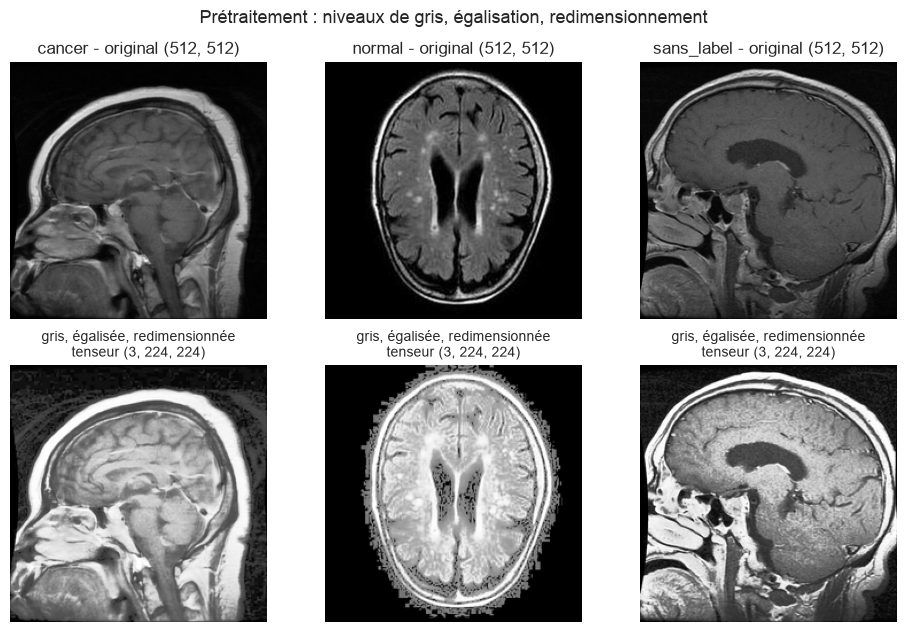

Tenseur normalisé : moyenne 0.20, écart-type 1.24 (dernière image affichée)


In [2]:
# Niveaux de gris et égalisation : réduction des biais liés à l'image
# (couleur, luminosité, contraste), voir la justification en section 5.
preprocess = preprocess_equalized

print("Moyenne ImageNet :", IMAGENET_MEAN)
print("Écart-type ImageNet :", IMAGENET_STD)

samples = manifest.groupby("subset").head(1)
figure, axes = plt.subplots(2, len(samples), figsize=(3.2 * len(samples), 6.4))
for column, (_, row) in enumerate(samples.iterrows()):
    with Image.open(row["filepath"]) as image:
        tensor = preprocess(image)
        axes[0, column].imshow(image.convert("RGB"))
        axes[0, column].set_title(f"{row['subset']} - original {image.size}")
        equalized = ImageOps.equalize(image.convert("L"))
        resized = equalized.resize(
            (IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.LANCZOS
        )
        axes[1, column].imshow(resized, cmap="gray", vmin=0, vmax=255)
        axes[1, column].set_title(
            f"gris, égalisée, redimensionnée\ntenseur {tuple(tensor.shape)}",
            fontsize=10,
        )
    axes[0, column].axis("off")
    axes[1, column].axis("off")
figure.suptitle(
    "Prétraitement : niveaux de gris, égalisation, redimensionnement",
    fontsize=13,
)
plt.tight_layout()
figure.savefig(FIGURES_DIR / "pretraitement.png", dpi=120, bbox_inches="tight")
plt.show()

print(
    f"Tenseur normalisé : moyenne {tensor.mean():.2f}, "
    f"écart-type {tensor.std():.2f} (dernière image affichée)"
)

## 3. Extraction des caractéristiques

L'extraction est implémentée dans `brain_mri.features` (`load_extractor`, `extract_features`). On prélève la sortie de deux couches du ResNet18 et on la résume par un **average pooling global**, ce qui donne un vecteur par image :

| Couche | Rôle | Dimension |
|---|---|---|
| `layer3` | Caractéristiques de niveau intermédiaire (textures, motifs) | 256 |
| `layer4` | Caractéristiques de haut niveau, dernière couche convolutive | 512 |

La mission recommande d'évaluer plusieurs couches d'extraction : la section 5 regarde ce que donne chacune sur les images annotées.

In [3]:
device = select_device()
print(f"Calcul sur : {device}")

extractor = load_extractor(device)

start = time.perf_counter()
features = extract_features(extractor, manifest["filepath"], device)
elapsed = time.perf_counter() - start

for name, matrix in features.items():
    print(f"{name} : {matrix.shape}, {matrix.dtype}")
images_per_second = len(manifest) / elapsed
print(f"{elapsed:.1f} s, soit {images_per_second:.1f} images par seconde")

Calcul sur : mps
layer3 : (1291, 256), float32
layer4 : (1291, 512), float32
5.5 s, soit 233.2 images par seconde


## 4. Sauvegarde

Chaque couche est enregistrée dans un fichier `.npz` qui contient les `image_id` **et** la matrice de features : l'alignement avec le manifeste reste ainsi dans un seul fichier.

In [4]:
saved_paths = save_features(manifest["image_id"], features)

# Relecture : les identifiants et la matrice doivent être identiques.
for matrix, path in zip(features.values(), saved_paths, strict=True):
    saved_ids, saved_matrix = load_features(path)
    assert (saved_ids == manifest["image_id"].to_numpy()).all()
    assert np.array_equal(saved_matrix, matrix)
print("Relecture réussie : identifiants et matrices identiques.")

Relecture réussie : identifiants et matrices identiques.


## 5. Vérification de l'exploitabilité

Avant de passer au clustering, on vérifie que les vecteurs sont valides, puis on compare les deux couches sur les **images annotées**, avec deux mesures :

- le **score de silhouette** des labels (cosinus), qui vaut 1 si les classes sont bien séparées et 0 si elles se recouvrent ;
- l'**écart de similarité cosinus** : similarité moyenne entre images de même classe moins similarité moyenne entre classes différentes.

Avec seulement 97 images annotées, ces mesures sont indicatives : elles servent à comparer les couches, pas à estimer une performance.

In [5]:
labeled = manifest["is_labeled"].to_numpy()
labels = manifest.loc[labeled, "label"].to_numpy()

rows = []
for name, matrix in features.items():
    labeled_matrix = matrix[labeled]
    normalized = labeled_matrix / np.linalg.norm(
        labeled_matrix, axis=1, keepdims=True
    )
    similarity = normalized @ normalized.T
    same_class = labels[:, None] == labels[None, :]
    off_diagonal = ~np.eye(len(labels), dtype=bool)

    rows.append(
        {
            "couche": name,
            "dimension": matrix.shape[1],
            "valeurs_non_finies": int((~np.isfinite(matrix)).sum()),
            "dimensions_constantes": int((matrix.std(axis=0) == 0).sum()),
            "norme_moyenne": np.linalg.norm(matrix, axis=1).mean(),
            "silhouette_cosinus": silhouette_score(
                labeled_matrix, labels, metric="cosine"
            ),
            "ecart_cosinus": similarity[same_class & off_diagonal].mean()
            - similarity[~same_class].mean(),
        }
    )

comparison = pd.DataFrame(rows).set_index("couche").round(3)
display(comparison)

,dimension,valeurs_non_finies,dimensions_constantes,norme_moyenne,silhouette_cosinus,ecart_cosinus
couche,,,,,,
layer3,256,0,0,2.439,0.160,0.011
layer4,512,0,0,28.878,0.146,0.039


`layer3` a la meilleure silhouette (0,160 contre 0,146), `layer4` le meilleur écart de similarité cosinus (0,039 contre 0,011). Les valeurs sont faibles dans les deux cas, ce qui n'a rien d'anormal avec des caractéristiques ImageNet non adaptées à l'IRM et seulement 97 images annotées.

### Les features portent-elles un signal ?

Deux preuves, sur les images annotées :

- une **projection PCA en 2D** (standardisation puis deux composantes), avec les images non annotées en gris pour situer les annotées dans l'ensemble ;
- un **modèle de référence** : une régression logistique évaluée par validation croisée stratifiée répétée, dont on retient l'AUC (0,5 = hasard).

La standardisation est placée **dans** la chaîne de traitement : elle est réajustée dans chaque pli, sans fuite d'information. Le label n'est converti en 0 / 1 que pour cette évaluation, sur les images annotées. Avec 97 images, ces mesures sont indicatives.

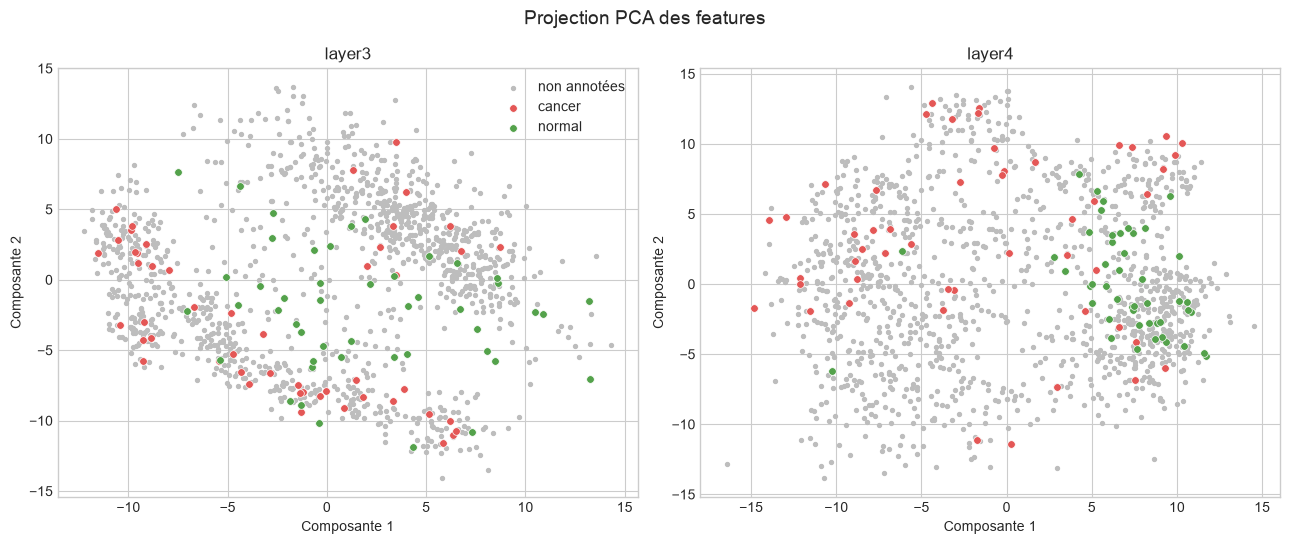

,auc_moyenne,ecart_type
couche,,
layer3,0.983,0.031
layer4,0.977,0.034


In [6]:
figure, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for axis, (name, matrix) in zip(axes, features.items(), strict=True):
    coordinates = PCA(n_components=2, random_state=0).fit_transform(
        StandardScaler().fit_transform(matrix)
    )
    axis.scatter(
        coordinates[~labeled, 0],
        coordinates[~labeled, 1],
        s=8,
        color="#BDBDBD",
        label="non annotées",
    )
    for label, color in (("cancer", "#E45756"), ("normal", "#54A24B")):
        mask = (manifest["label"] == label).to_numpy()
        axis.scatter(
            coordinates[mask, 0],
            coordinates[mask, 1],
            s=30,
            color=color,
            edgecolor="white",
            linewidth=0.5,
            label=label,
        )
    axis.set(title=name, xlabel="Composante 1", ylabel="Composante 2")
axes[0].legend()
figure.suptitle("Projection PCA des features", fontsize=14)
plt.tight_layout()
figure.savefig(FIGURES_DIR / "pca-features.png", dpi=120, bbox_inches="tight")
plt.show()

evaluation_target = (labels == "cancer").astype(int)
cross_validation = RepeatedStratifiedKFold(
    n_splits=5, n_repeats=10, random_state=42
)
baseline_rows = []
for name, matrix in features.items():
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    scores = cross_val_score(
        model,
        matrix[labeled],
        evaluation_target,
        cv=cross_validation,
        scoring="roc_auc",
    )
    baseline_rows.append(
        {
            "couche": name,
            "auc_moyenne": scores.mean(),
            "ecart_type": scores.std(),
        }
    )
display(pd.DataFrame(baseline_rows).set_index("couche").round(3))

Le modèle de référence atteint une AUC de 0,983 ± 0,031 sur `layer3` et 0,977 ± 0,034 sur `layer4` : les caractéristiques portent un signal. `layer3` est légèrement devant, mais l'écart est inférieur à l'écart-type.

### Justification du prétraitement

On compare trois prétraitements sur les images annotées, avec le même modèle de référence que ci-dessus. La colonne « descripteurs seuls » donne l'AUC d'un modèle qui ne voit que la luminosité, le contraste et la part de fond, **calculés sur l'image après prétraitement** : elle mesure l'indice parasite qui reste. Si l'égalisation le réduit sans dégrader les embeddings, elle est justifiée.

In [7]:
def cross_validated_auc(matrix: np.ndarray) -> tuple[float, float]:
    """AUC moyenne et écart-type en validation croisée."""
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    scores = cross_val_score(
        model,
        matrix,
        evaluation_target,
        cv=cross_validation,
        scoring="roc_auc",
    )
    return scores.mean(), scores.std()


def gray_descriptors(filepath, equalize: bool) -> tuple[float, float, float]:
    """Luminosité, contraste et part de fond d'une image en niveaux de gris."""
    with Image.open(filepath) as image:
        gray = image.convert("L")
        if equalize:
            gray = ImageOps.equalize(gray)
        pixels = np.asarray(gray, dtype=float)
    return (
        pixels.mean(),
        pixels.std(),
        (pixels < BACKGROUND_LEVEL).mean(),
    )


variants = {
    "RGB d'origine": (preprocess_rgb, False),
    "Niveaux de gris": (preprocess_gray, False),
    "Niveaux de gris + égalisation (retenu)": (preprocess_equalized, True),
}
labeled_paths = manifest.loc[labeled, "filepath"]

comparison_rows = []
for variant_name, (transform, equalize) in variants.items():
    row = {"prétraitement": variant_name}
    variant_features = extract_features(
        extractor, labeled_paths, device, transform
    )
    for layer, matrix in variant_features.items():
        mean, std = cross_validated_auc(matrix)
        row[layer] = f"{mean:.3f} ± {std:.3f}"
    descriptors_matrix = np.array(
        [gray_descriptors(path, equalize) for path in labeled_paths]
    )
    mean, std = cross_validated_auc(descriptors_matrix)
    row["descripteurs seuls"] = f"{mean:.3f} ± {std:.3f}"
    comparison_rows.append(row)

display(pd.DataFrame(comparison_rows).set_index("prétraitement"))

,layer3,layer4,descripteurs seuls
prétraitement,,,
RGB d'origine,0.974 ± 0.040,0.949 ± 0.055,0.819 ± 0.095
Niveaux de gris,0.974 ± 0.040,0.949 ± 0.055,0.819 ± 0.095
Niveaux de gris + égalisation (retenu),0.983 ± 0.031,0.977 ± 0.034,0.648 ± 0.136


## 6. Cartes d'activation et d'attention

Deux regards sur ce que voit le ResNet18, sans utiliser les labels ni le clustering. Le but n'est pas d'interpréter les images médicalement, mais de vérifier que le réseau réagit à des structures visibles. Les images passent par le prétraitement retenu (niveaux de gris, égalisation d'histogramme, normalisation ImageNet), avec le ResNet18 **complet** : l'extraction des caractéristiques de la section 3 n'est pas modifiée.

In [8]:
classifier = load_classifier(device)


def load_input(filepath):
    """Prétraite une image avec le prétraitement retenu."""
    with Image.open(filepath) as image:
        return preprocess_equalized(image)

### Cartes d'activation de `layer4`

Ces cartes montrent quelles zones de l'image activent le plus fortement les filtres de la dernière couche convolutive. Une couche produit une carte par canal (512 pour `layer4`) ; pour chaque image annotée, on affiche à droite de l'image les **16 canaux les plus actifs** (carte moyenne la plus élevée). Les cartes de `layer4` font 7 × 7 : elles sont agrandies par interpolation bilinéaire pour être lisibles.

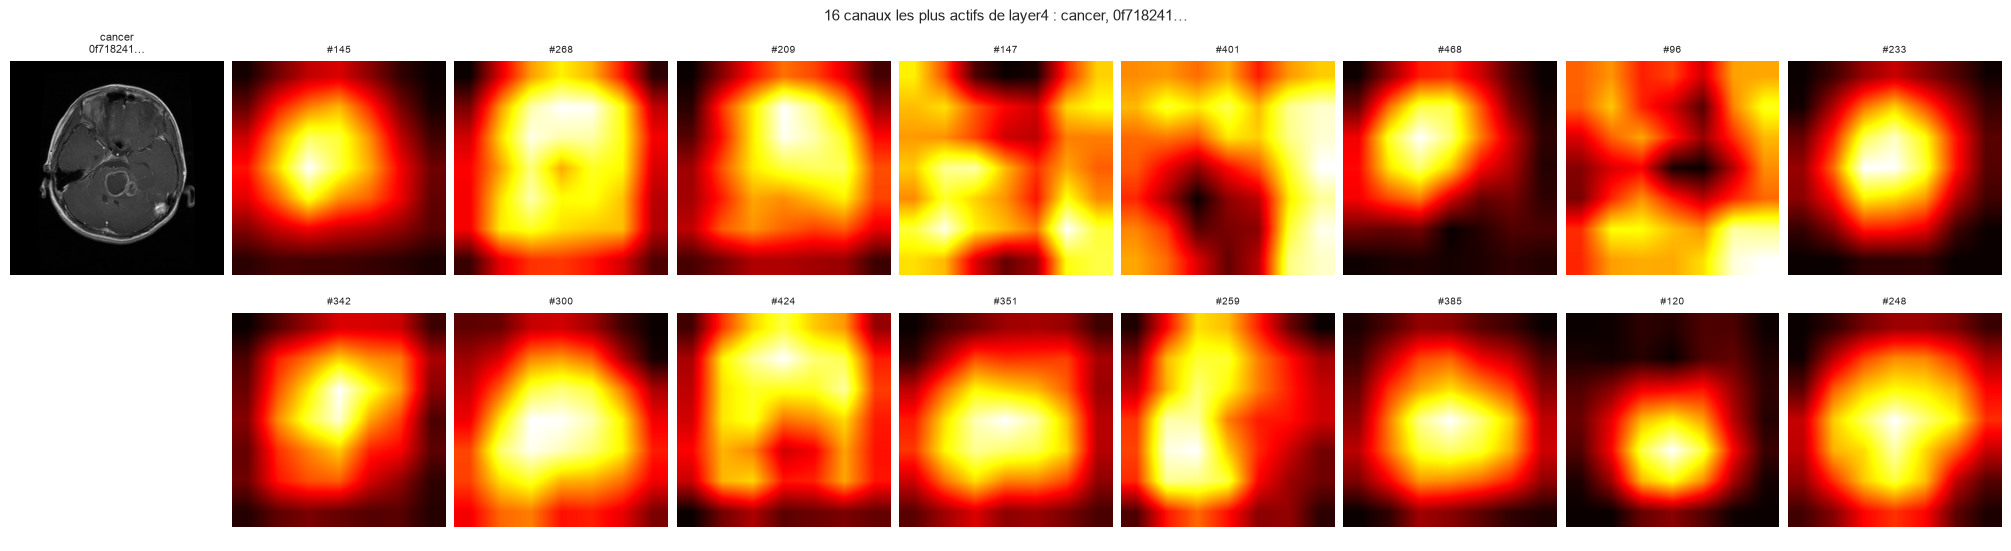

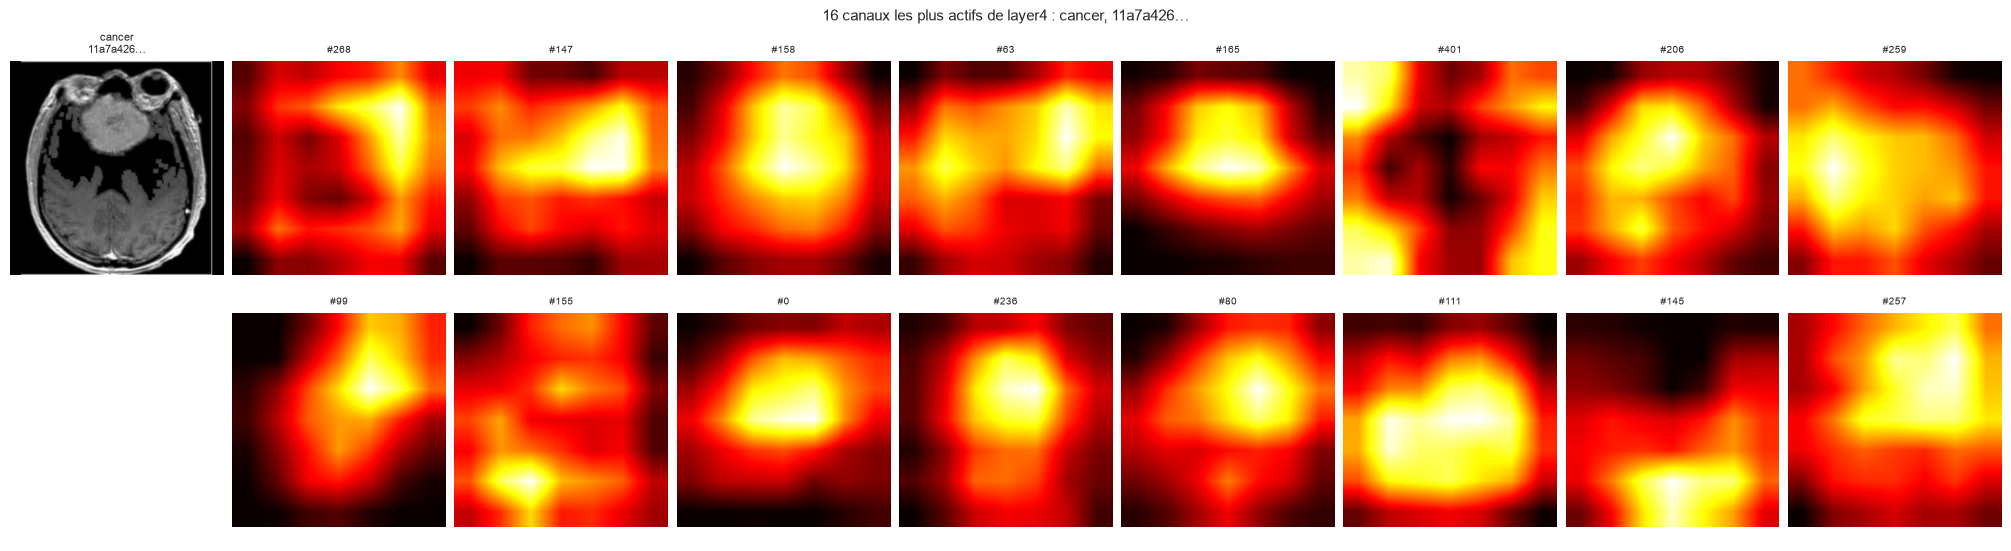

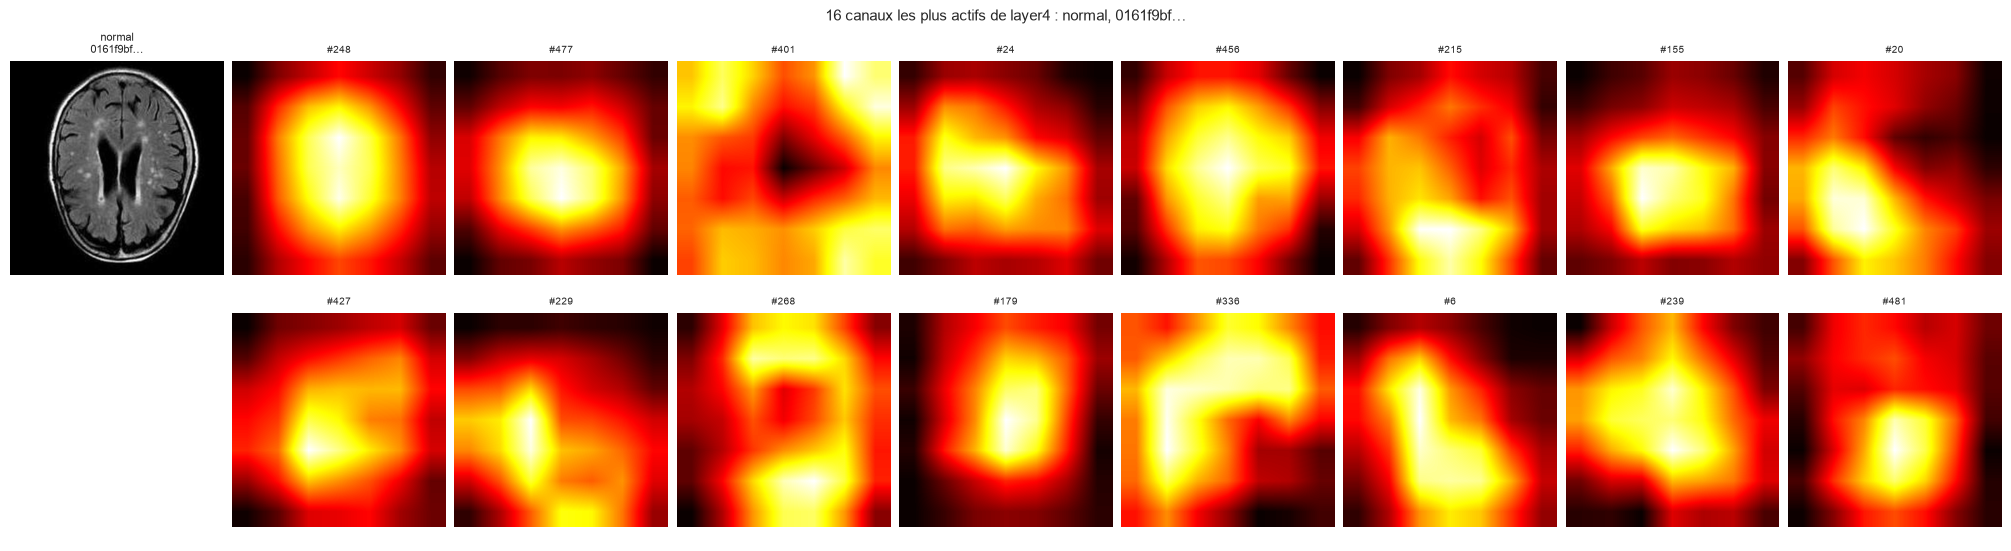

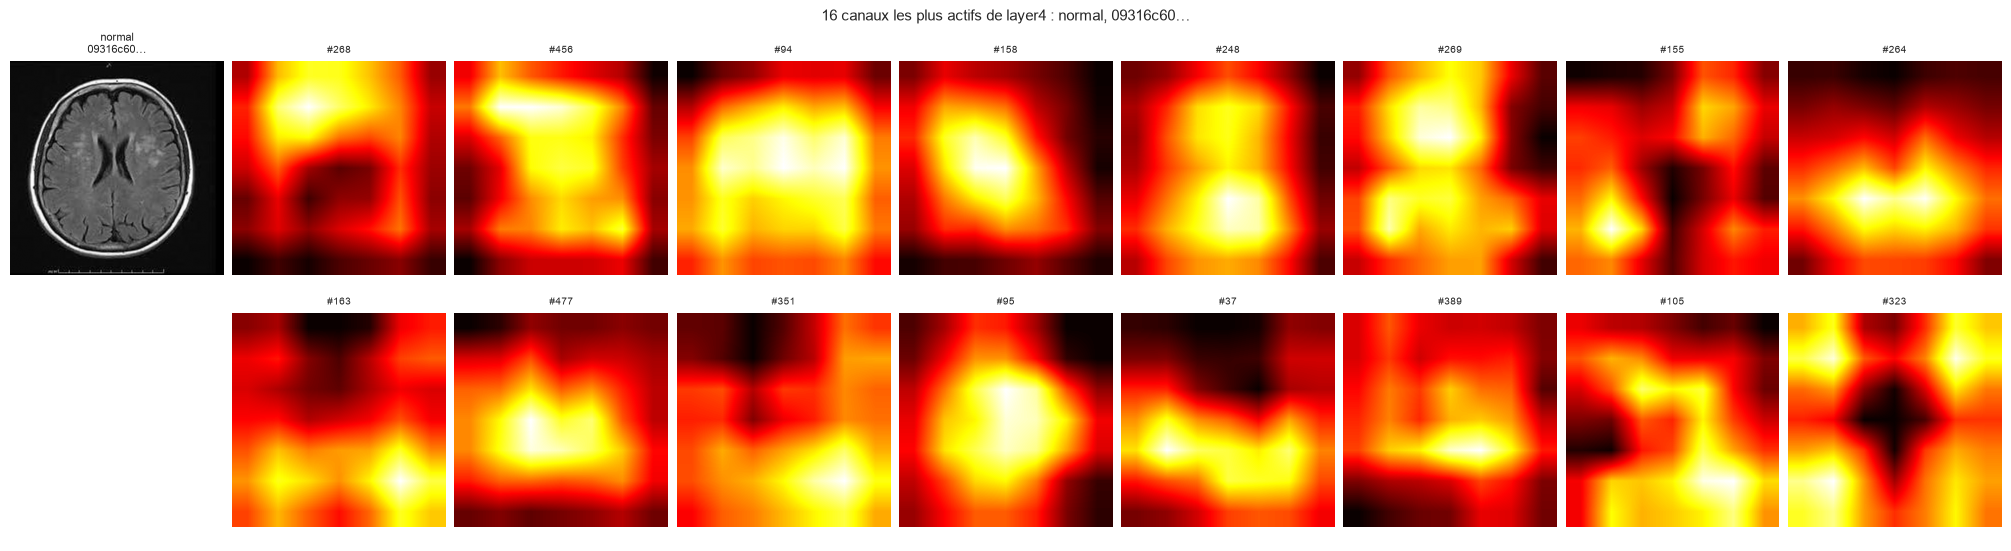

In [9]:
annotated = {
    label: manifest[manifest["label"] == label]
    for label in ("cancer", "normal")
}
activation_samples = pd.concat(
    [annotated["cancer"].iloc[2:4], annotated["normal"].iloc[:2]]
)

for _, row in activation_samples.iterrows():
    maps = feature_maps(classifier, load_input(row["filepath"]), "layer4")
    top_channels = maps.mean(dim=(1, 2)).argsort(descending=True)[:16]

    figure, axes = plt.subplots(2, 9, figsize=(20, 5.4), layout="constrained")
    with Image.open(row["filepath"]) as image:
        axes[0, 0].imshow(image.convert("L"), cmap="gray")
    axes[0, 0].set_title(f"{row['label']}\n{row['image_id'][:8]}…", fontsize=8)
    axes[0, 0].axis("off")
    axes[1, 0].axis("off")
    for rank, channel in enumerate(top_channels):
        axis = axes[rank // 8, rank % 8 + 1]
        axis.imshow(maps[channel].numpy(), cmap="hot", interpolation="bilinear")
        axis.set_title(f"#{channel.item()}", fontsize=7)
        axis.axis("off")
    figure.suptitle(
        f"16 canaux les plus actifs de layer4 : {row['label']}, "
        f"{row['image_id'][:8]}…",
        fontsize=11,
    )
    figure.savefig(
        FIGURES_DIR
        / f"cartes-activation-layer4-{row['label']}-{row['image_id'][:8]}.png",
        dpi=110,
        bbox_inches="tight",
    )
    plt.show()

Les canaux les plus actifs forment surtout des taches larges et lisses **centrées** sur l'intérieur de la tête. Quelques-uns ont la forme d'un anneau : ils s'activent sur les bords de l'image et restent éteints au centre (par exemple #401). Un canal, #268, figure parmi les 16 plus actifs des quatre images, `cancer` comme `normal` : il réagit à la structure générale d'une IRM de tête plutôt qu'à une classe.

### Où le réseau concentre son attention

**Grad-CAM** affiche les zones de l'image qui influencent le plus la sortie du réseau : les cartes de caractéristiques de `layer4` sont pondérées par le gradient du score de la classe prédite, et seules les contributions positives sont gardées (ReLU). La carte est normalisée entre 0 et 1, puis agrandie de 7 × 7 à 224 × 224 par interpolation bilinéaire : elle reste grossière.

La classe prédite est une classe d'**ImageNet** (objets et animaux du quotidien) : elle n'a **aucun sens médical**. Une carte se lit comme « les zones qui comptent pour le réseau », pas comme un indice de cancer.

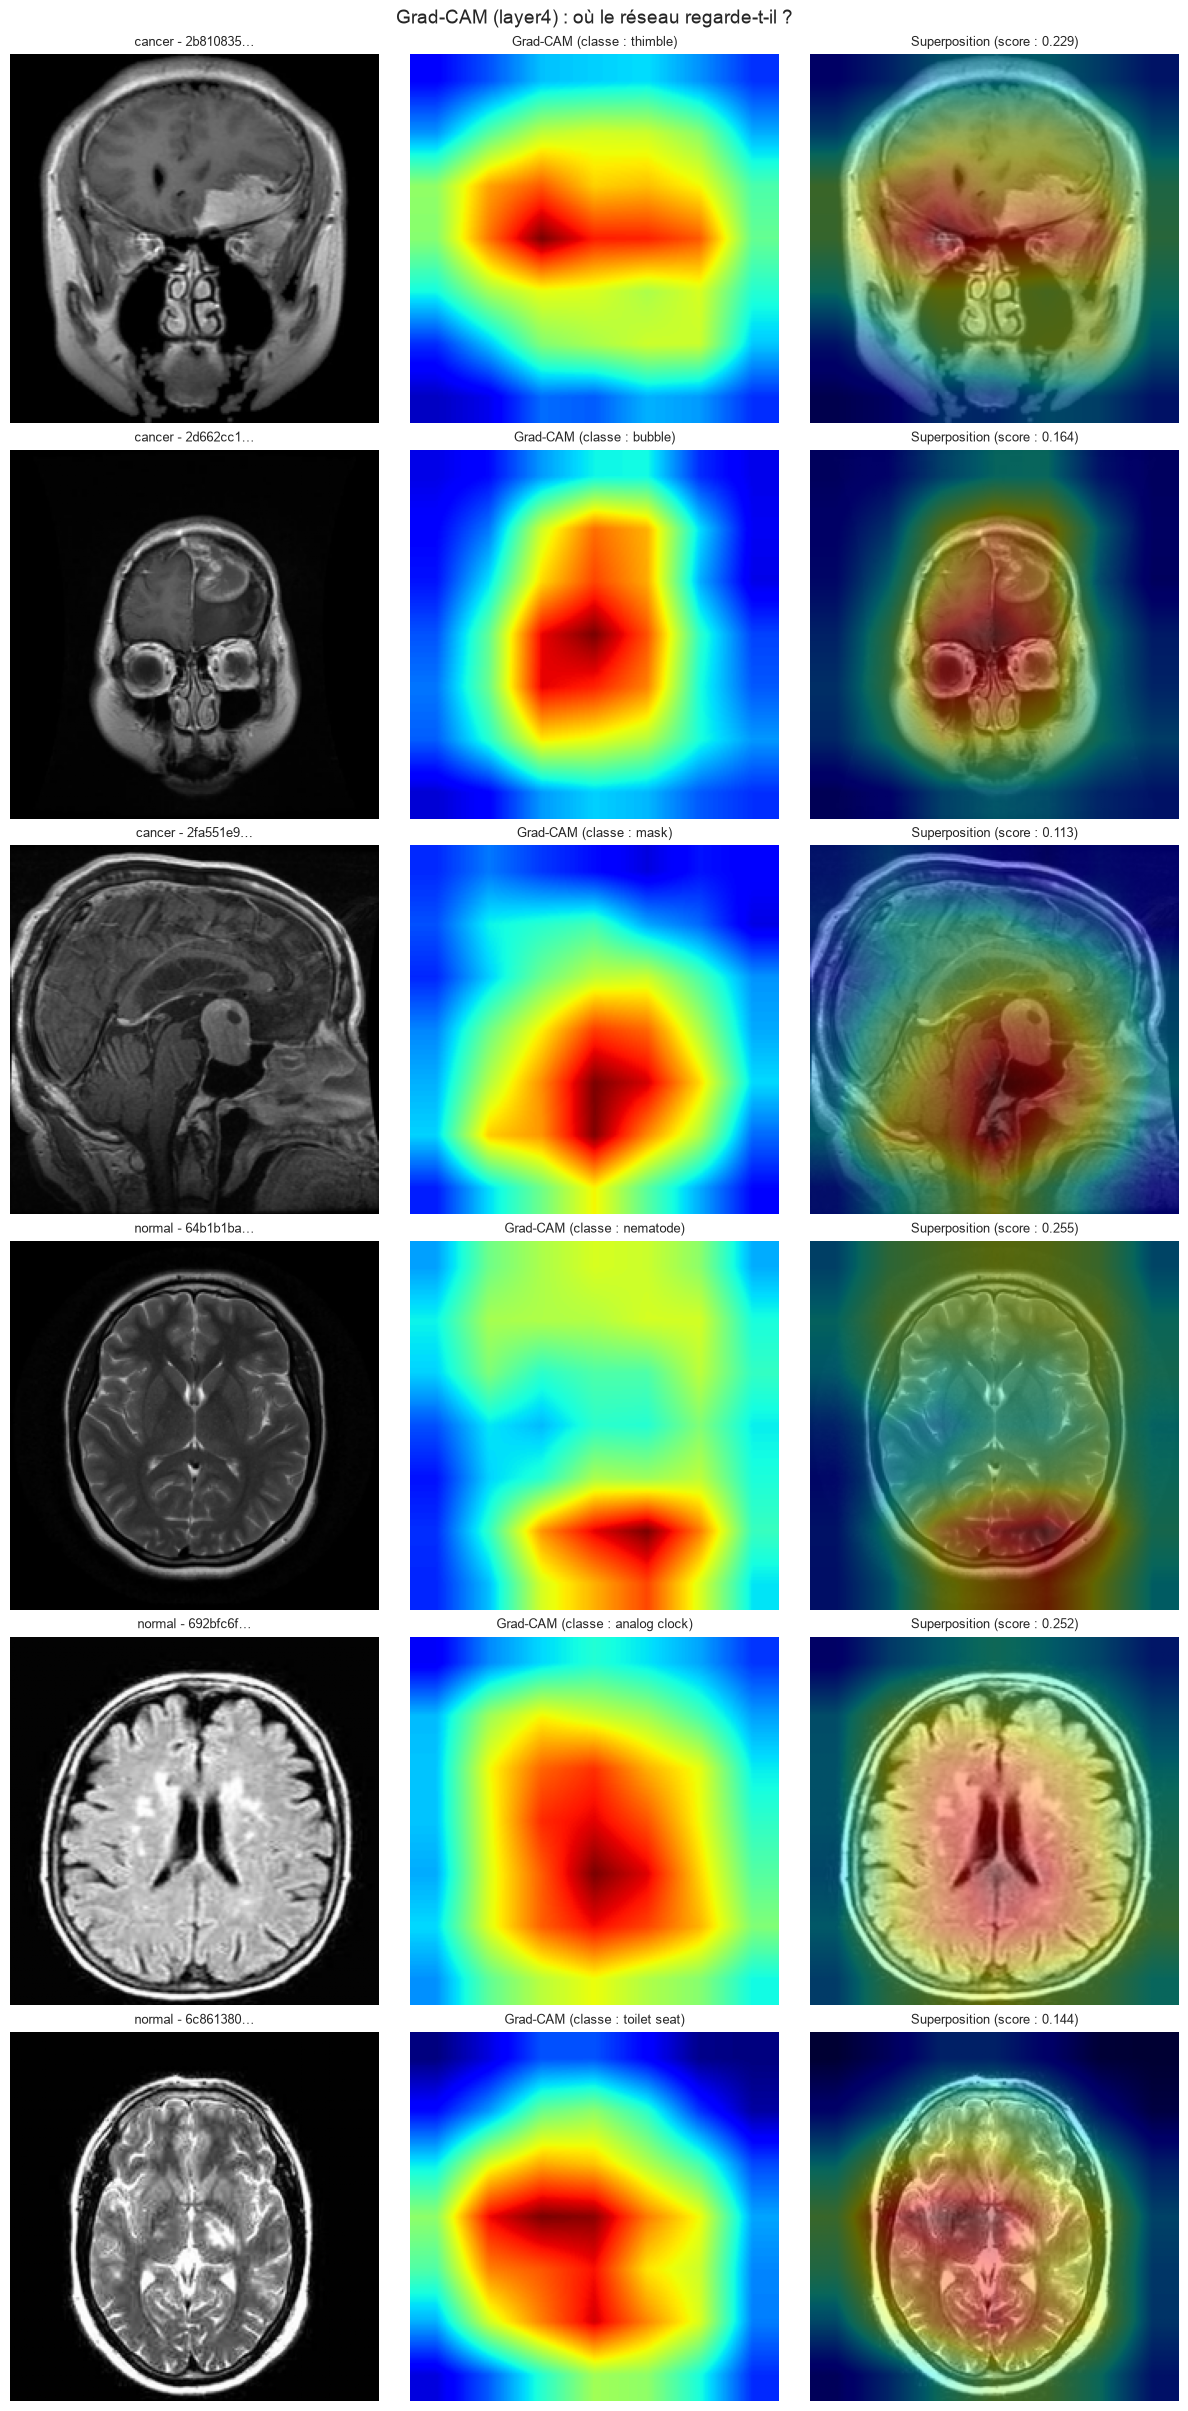

In [10]:
gradcam_samples = pd.concat(
    [annotated["cancer"].iloc[6:9], annotated["normal"].iloc[23:26]]
)
batch = torch.stack(
    [load_input(path) for path in gradcam_samples["filepath"]]
).to(device)
cams, predicted, scores = grad_cam(classifier, batch, "layer4")

figure, axes = plt.subplots(
    len(gradcam_samples),
    3,
    figsize=(12, 4 * len(gradcam_samples)),
    layout="constrained",
)
for row, (_, sample) in enumerate(gradcam_samples.iterrows()):
    with Image.open(sample["filepath"]) as image:
        base = np.asarray(image.convert("L").resize((IMAGE_SIZE, IMAGE_SIZE)))
    axes[row, 0].imshow(base, cmap="gray")
    axes[row, 0].set_title(
        f"{sample['label']} - {sample['image_id'][:8]}…", fontsize=9
    )
    axes[row, 1].imshow(cams[row], cmap="jet", vmin=0, vmax=1)
    axes[row, 1].set_title(
        f"Grad-CAM (classe : {IMAGENET_CLASSES[predicted[row]]})", fontsize=9
    )
    axes[row, 2].imshow(base, cmap="gray")
    axes[row, 2].imshow(cams[row], cmap="jet", alpha=0.4, vmin=0, vmax=1)
    axes[row, 2].set_title(
        f"Superposition (score : {scores[row]:.3f})", fontsize=9
    )
for axis in axes.ravel():
    axis.axis("off")
figure.suptitle("Grad-CAM (layer4) : où le réseau regarde-t-il ?", fontsize=14)
figure.savefig(
    FIGURES_DIR / "grad-cam-layer4.png", dpi=110, bbox_inches="tight"
)
plt.show()

Les zones chaudes sont de larges zones à l'intérieur de la tête, qui couvrent souvent une grande partie du cerveau. Elles ne se superposent pas systématiquement à la lésion visible des images `cancer`. Les scores de la classe prédite sont faibles (de 0,11 à 0,25), ce qui est attendu : cette classe n'a aucun rapport avec l'image.

## 7. Coût de calcul

Le débit mesuré permet d'estimer le temps nécessaire pour un passage à l'échelle. Cette estimation sera reprise dans le support de présentation (4 millions d'images, budget de 5 000 €).

In [11]:
TARGET_IMAGES = 4_000_000

estimated_hours = TARGET_IMAGES / images_per_second / 3600
print(f"Débit mesuré : {images_per_second:.1f} images par seconde ({device})")
print(
    f"Extraction de {TARGET_IMAGES:,} images sur cette machine : "
    f"environ {estimated_hours:.0f} heures"
)

Débit mesuré : 233.2 images par seconde (mps)
Extraction de 4,000,000 images sur cette machine : environ 5 heures


## Conclusion de l'étape

### Synthèse

- **Prétraitement.** Les **1 291 images** retenues (le manifeste dédupliqué, sans l'image inexploitable) sont converties en niveaux de gris, égalisées par histogramme, redimensionnées en 224 × 224 puis normalisées avec les statistiques d'ImageNet, avant de passer dans un **ResNet18 gelé**. Deux matrices en résultent : `layer3` (1 291 × 256) et `layer4` (1 291 × 512). Elles sont sauvegardées en `.npz` avec les `image_id`, et la relecture est identique.
- Les vecteurs sont valides : aucune valeur non finie et aucune dimension constante.
- **Justification de l'égalisation.** Sur les images d'origine, un modèle qui ne voit que la luminosité, le contraste et la part de fond atteint une AUC de **0,819 ± 0,095** : ces indices suffisent à séparer en grande partie les classes annotées. Après égalisation, cette AUC tombe à **0,648 ± 0,136**, alors que celle des caractéristiques ne baisse pas (`layer3` : 0,983 contre 0,974 ; `layer4` : 0,977 contre 0,949). Le signal ne vient donc pas surtout de la luminosité ni du contraste globaux. L'égalisation ne supprime pas tout le biais : il reste la part de fond, et elle ne corrige pas les différences de séquence ou de source d'acquisition.
- **Couches.** `layer3` a la meilleure silhouette (0,160 contre 0,146), `layer4` le meilleur écart de similarité cosinus (0,039 contre 0,011). Les valeurs sont faibles dans les deux cas, ce qui n'a rien d'anormal avec des caractéristiques ImageNet non adaptées à l'IRM et seulement 97 images annotées.
- **Exploitabilité.** Un modèle linéaire de référence, évalué par validation croisée sur les images annotées, atteint une AUC de **0,983 ± 0,031** sur `layer3` et **0,977 ± 0,034** sur `layer4` : les caractéristiques portent un signal. `layer3` est légèrement devant, mais l'écart est inférieur à l'écart-type.
- **Cartes d'activation et d'attention.** Les canaux les plus actifs de `layer4` sont surtout des taches larges centrées sur l'intérieur de la tête, avec quelques cartes en anneau sur les bords. Grad-CAM met en évidence de larges zones à l'intérieur de la tête, sans se superposer systématiquement à la lésion visible. La classe ImageNet prédite n'a pas de sens médical (scores de 0,11 à 0,25) : ces cartes ne sont pas un indice de cancer.
- Le débit mesuré est de **233,2 images par seconde** (GPU Apple, calcul MPS), soit environ **5 heures** pour 4 millions d'images sur cette machine. Il varie d'une exécution à l'autre (de 233 à 286 images par seconde sur trois exécutions).

### Décision

Le prétraitement retenu est : niveaux de gris, égalisation d'histogramme, redimensionnement, normalisation ImageNet. Les caractéristiques retenues pour l'étape suivante sont celles de `layer4` d'un ResNet18 gelé (512 dimensions), et aucune image annotée n'est retirée. À surveiller lors du clustering : des groupes pourraient encore refléter des différences de source ou de contraste plutôt que la pathologie.
